# 02 Valores em falta e transformações

O que faço às linhas sem CHL e que transformações merecem entrar. Cada variante é testada em leave-one-year-out cross-validation com a Logistic Regression (C=3, class_weight balanced), só com 2013-2019 e só com linhas completas.

As tabelas mostram o AUC de cada ano, a média e a diferença média face à referência (Δ médio). O desvio entre anos é de cerca de 0.08, por isso uma diferença de 0.01 não quer dizer nada sozinha.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesClassifier

sys.path.insert(0, "../task1/best_model")        # as funções que o train.py e o predict também usam
sys.path.insert(0, "../task1/training_code")
import utils, cv

AZUL, VERM = "#0072B2", "#D55E00"          # paleta Okabe-Ito, legível por daltónicos
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "normal", "axes.titlelocation": "left",
    "figure.figsize": (3.4, 2.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.unicode_minus": False, "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def guardar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

In [2]:
raw = pd.read_csv("../data/classification_task1_train.csv", parse_dates=["Date"])
df = raw[raw["Year"] < 2020].copy()          # 2020 fica de fora: é o test set final
df["mes"] = df["Date"].dt.month
comp = df[df["CHL"].notna()].copy()          # linhas completas: as únicas que os modelos usam
falta = df[df["CHL"].isna()].copy()
print(f"{len(df)} linhas: {len(comp)} completas e {len(falta)} sem CHL nem incerteza")

905 linhas: 476 completas e 429 sem CHL nem incerteza


In [3]:
S0 = dict(utils.DEFAULT_SPEC, unc="log")      # ponto de partida dos primeiros testes (log no CHL e na incerteza)

def auc_loyo(spec, C=3.0):
    """AUC de cada ano, com o ano inteiro de fora em cada fold (só linhas completas)."""
    auc, _ = cv.loyo(comp, lambda tr, va: utils.score(utils.fit_logreg(tr, spec, C), va))
    return auc

def tabela(variantes, ref):
    """AUC de cada ano, a média e a diferença média face à referência (a primeira linha)."""
    base = auc_loyo(ref)
    linhas = {"referência": {**{int(y): v for y, v in base.dropna().items()}, "média": base.mean(), "Δ médio": 0.0}}
    for nome, spec in variantes.items():
        a = auc_loyo(spec)
        linhas[nome] = {**{int(y): v for y, v in a.dropna().items()}, "média": a.mean(), "Δ médio": (a - base).mean()}
    return pd.DataFrame(linhas).T.round(3)

## 1. Valores em falta

Onde faltam o CHL e a incerteza?

In [4]:
print("CHL e incerteza faltam sempre juntas:", bool((df["CHL"].isna() == df["CHL_uncertainty"].isna()).all()))
for chave, nome in [("Year", "ano"), ("mes", "mês"), ("spatial_cluster", "cluster")]:
    p = 100 * df.groupby(chave)["CHL"].apply(lambda s: s.isna().mean())
    print(f"% de linhas sem CHL por {nome}: de {p.min():.0f}% ({nome} {p.idxmin()}) a {p.max():.0f}% ({nome} {p.idxmax()})")

CHL e incerteza faltam sempre juntas: True
% de linhas sem CHL por ano: de 41% (ano 2017) a 62% (ano 2014)
% de linhas sem CHL por mês: de 37% (mês 9) a 59% (mês 1)
% de linhas sem CHL por cluster: de 42% (cluster 2) a 64% (cluster 1)


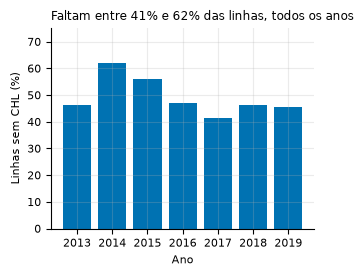

In [5]:
por_ano = 100 * df.groupby("Year")["CHL"].apply(lambda s: s.isna().mean())
fig, ax = plt.subplots()
ax.bar(por_ano.index, por_ano, color=AZUL)
ax.set(xlabel="Ano", ylabel="Linhas sem CHL (%)", xticks=por_ano.index, ylim=(0, 75),
       title=f"Faltam entre {por_ano.min():.0f}% e {por_ano.max():.0f}% das linhas, todos os anos")
guardar(fig, "07_falta_por_ano")

In [6]:
print(f"HAB nas completas: {comp['HAB'].mean():.1%} ({comp['HAB'].sum()}/{len(comp)}); nas incompletas: {falta['HAB'].mean():.1%} ({falta['HAB'].sum()}/{len(falta)})")

HAB nas completas: 13.0% (62/476); nas incompletas: 10.5% (45/429)


O CHL e a incerteza faltam sempre juntos, em 429 das 905 linhas (47%). A falta está espalhada: por ano vai de 41% a 62%, por mês de 37% a 59% e por cluster de 42% a 64% (o cluster 1 tem só 11 linhas). Não vejo nenhum ano, mês ou cluster que a explique. A taxa de HAB é parecida nas linhas completas e nas incompletas (13.0% contra 10.5%).

O test set só tem linhas completas, por isso a pergunta útil é se treinar também com as incompletas ajuda. Preencho o CHL e a incerteza com a mediana do training set, com e sem um indicador de falta, e valido só nas linhas completas.

In [7]:
def treinar_com_incompletas(spec):
    """Treina com as linhas completas e também com as sem CHL dos anos de treino (a mediana do treino preenche a falta)."""
    def fit_score(tr, va):
        extra = falta[~falta["Year"].isin(va["Year"].unique())]
        return utils.score(utils.fit_logreg(pd.concat([tr, extra]), spec), va)
    return cv.loyo(comp, fit_score)[0]

res = pd.DataFrame({"só completas": auc_loyo(S0), "todas, mediana": treinar_com_incompletas(S0),
                    "todas, mediana + indicador de falta": treinar_com_incompletas({**S0, "chl_flag": True})}).dropna()
res.T.assign(média=res.mean()).round(3)

,2013,2015,2016,2018,2019,média
só completas,0.661,0.773,0.860,0.903,0.786,0.797
"todas, mediana",0.668,0.753,0.841,0.893,0.793,0.790
"todas, mediana + indicador de falta",0.666,0.760,0.835,0.892,0.785,0.788


In [8]:
med = utils.fallback_medians(comp)
print("medianas de reserva (treino 2013-2019):", {k: round(v, 2) for k, v in med.items()})
estado = utils.fit_state(comp, S0)
sem_chl = comp.iloc[[0]].assign(CHL=np.nan, CHL_uncertainty=np.nan)
cluster_novo = comp.iloc[[0]].assign(spatial_cluster=9)
print("linha sem CHL: sem NaN na matriz?", not np.isnan(utils.transform(sem_chl, estado)).any())
print("cluster novo (9): colunas do one-hot =", utils.transform(cluster_novo, estado)[0, -len(estado["clusters"]):])

medianas de reserva (treino 2013-2019): {'CHL': 2.98, 'CHL_uncertainty': 32.97}
linha sem CHL: sem NaN na matriz? True
cluster novo (9): colunas do one-hot = [0. 0. 0. 0. 0. 0.]


Treinar com as linhas incompletas não ajuda: 0.790 com a mediana e 0.788 com o indicador de falta, contra 0.797 só com as completas. A diferença é pequena, mas não ganho nada, e treinar só com as completas tem uma vantagem: o training set vem da mesma população do test set.

Decisão: training e validation só com as 476 linhas completas.

O `predict` precisa de uma rede de segurança, porque o verificador envia linhas com NaN. Se chegar uma linha sem CHL, uso a mediana do training set (2.98 mg/m³ no CHL e 32.97 na incerteza). Nunca atua numa linha completa.

## 2. Transformações

Uma de cada vez, sempre contra a mesma referência: log no CHL e na incerteza, z-score, 2 harmónicos de sazonalidade e o cluster em one-hot.

### Log

O log ajuda no CHL e na incerteza?

CHL: mediana 2.98, máximo 62.7 mg/m³


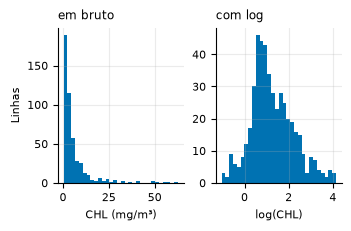

In [9]:
print(f"CHL: mediana {comp['CHL'].median():.2f}, máximo {comp['CHL'].max():.1f} mg/m³")
fig, ax = plt.subplots(1, 2, figsize=(3.4, 2.2), layout="constrained")
ax[0].hist(comp["CHL"], bins=30, color=AZUL); ax[1].hist(np.log(comp["CHL"]), bins=30, color=AZUL)
ax[0].set(xlabel="CHL (mg/m³)", ylabel="Linhas", title="em bruto")
ax[1].set(xlabel="log(CHL)", title="com log")
guardar(fig, "08_log_chl")

In [10]:
tabela({"CHL em bruto": {**S0, "CHL": "raw"}, "incerteza em bruto": {**S0, "unc": "raw"},
        "CHL e incerteza em bruto": {**S0, "CHL": "raw", "unc": "raw"}}, ref=S0)

,2013,2015,2016,2018,2019,média,Δ médio
referência,0.661,0.773,0.860,0.903,0.786,0.797,0.000
CHL em bruto,0.639,0.707,0.840,0.884,0.801,0.774,-0.023
incerteza em bruto,0.673,0.773,0.858,0.898,0.784,0.797,0.001
CHL e incerteza em bruto,0.654,0.707,0.837,0.876,0.798,0.774,-0.022


O CHL tem muitos valores baixos e poucos muito altos (mediana 2.98, máximo 62.7 mg/m³), e com log fica mais simétrico (figura). Sem o log, o AUC médio cai de 0.797 para 0.774. A incerteza já é mais simétrica, e em bruto o AUC não muda (0.797).

Decisão: log só no CHL. A incerteza fica em bruto.

In [11]:
SPEC = {**S0, "unc": "raw"}        # log só no CHL
assert SPEC == utils.DEFAULT_SPEC          # é o que o utils.py usa por defeito

### Z-score

Para a Logistic Regression o z-score faz falta? E as árvores?

In [12]:
for C in (3.0, 0.05):
    print(f"C={C}: AUC médio {auc_loyo(SPEC, C).mean():.3f} com z-score, {auc_loyo({**SPEC, 'zscore': False}, C).mean():.3f} sem z-score")

def extra_trees_auc(com_zscore):
    def fit_score(tr, va):
        med = utils.fallback_medians(tr)
        X, Xv = utils.tree_matrix(tr, med), utils.tree_matrix(va, med)
        if com_zscore:
            mu, sd = X.mean(0), X.std(0)
            X, Xv = (X - mu) / sd, (Xv - mu) / sd
        arvores = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt", random_state=0)
        return arvores.fit(X, tr["HAB"]).predict_proba(Xv)[:, 1]
    return cv.loyo(comp, fit_score)[0].mean()

print(f"Extra Trees: AUC médio {extra_trees_auc(False):.4f} em bruto, {extra_trees_auc(True):.4f} com z-score")

C=3.0: AUC médio 0.797 com z-score, 0.795 sem z-score
C=0.05: AUC médio 0.779 com z-score, 0.781 sem z-score


Extra Trees: AUC médio 0.8048 em bruto, 0.8048 com z-score


Com C=3 o AUC é 0.797 com z-score e 0.795 sem. O Extra Trees dá exatamente o mesmo em bruto e normalizado (0.8048), porque um split só compara valores de uma feature.

Decisão: z-score só na Logistic Regression, ajustado no training set de cada fold, para o `C` pesar o mesmo em todas as features. Não é para ganhar AUC, porque não ganha.

### Sazonalidade

O `YDOY` do ficheiro é o cosseno do dia do ano. Chega só ele? Antes disso confirmo a convenção do ficheiro, porque vou construir o seno com a mesma.

In [13]:
dia = df["Date"].dt.dayofyear
print(f"YDOY do ficheiro contra cos(2π·dia/365) calculado de Date: diferença máxima {np.abs(df['YDOY'] - np.cos(2 * np.pi * dia / 365)).max():.1e}")
print(f"com /366 a diferença máxima seria {np.abs(df['YDOY'] - np.cos(2 * np.pi * dia / 366)).max():.3f}")
print(f"anos bissextos nos dados: {sorted(df.loc[df['Date'].dt.is_leap_year, 'Year'].unique())}; linhas no dia 366: {int((dia == 366).sum())}")

YDOY do ficheiro contra cos(2π·dia/365) calculado de Date: diferença máxima 5.0e-10
com /366 a diferença máxima seria 0.013
anos bissextos nos dados: [np.int64(2016)]; linhas no dia 366: 0


O `YDOY` coincide com cos(2π·dia/365) calculado a partir de `Date` (diferença máxima 5.0e-10). Com 366 a diferença seria 0.013, por isso a convenção é 365. O ano bissexto 2016 está nos dados, mas nenhuma linha cai no dia 366. Construo o seno com a mesma convenção.

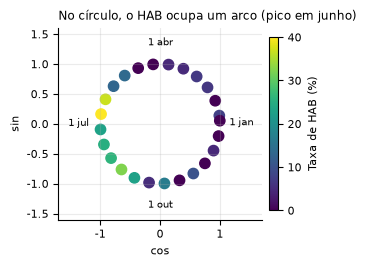

In [14]:
NOMES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro", "novembro", "dezembro"]
comp["periodo"] = (comp["Date"].dt.dayofyear - 1) // 15              # 25 períodos de 15 dias
t = comp.groupby("periodo")["HAB"].agg(taxa="mean", linhas="size")
t["dia"] = 15 * t.index + 8
t["cos"], t["sin"] = np.cos(2 * np.pi * t["dia"] / 365), np.sin(2 * np.pi * t["dia"] / 365)
mes_pico = pd.to_datetime(f"2019-{int(t.loc[t['taxa'].idxmax(), 'dia'])}", format="%Y-%j").month
fig, ax = plt.subplots(figsize=(3.2, 3.0))
pontos = ax.scatter(t["cos"], t["sin"], c=100 * t["taxa"], cmap="viridis", s=55)
for nome, d in [("1 jan", 1), ("1 abr", 91), ("1 jul", 182), ("1 out", 274)]:
    ax.text(1.36 * np.cos(2 * np.pi * d / 365), 1.36 * np.sin(2 * np.pi * d / 365), nome, ha="center", va="center", fontsize=7)
ax.set(xlim=(-1.7, 1.7), ylim=(-1.6, 1.6), aspect="equal", xlabel="cos", ylabel="sin",
       title=f"No círculo, o HAB ocupa um arco (pico em {NOMES[mes_pico - 1]})")
fig.colorbar(pontos, label="Taxa de HAB (%)", shrink=0.75, pad=0.03); guardar(fig, "09_sazonalidade_circulo")

In [15]:
tabela({"sem sazonalidade": {**SPEC, "season": []}, "só cos1 (o YDOY)": {**SPEC, "season": ["cos1"]},
        "1 harmónico (cos1, sin1)": {**SPEC, "season": ["cos1", "sin1"]},
        "3 harmónicos": {**SPEC, "season": ["cos1", "sin1", "cos2", "sin2", "cos3", "sin3"]}}, ref=SPEC)

,2013,2015,2016,2018,2019,média,Δ médio
referência,0.673,0.773,0.858,0.898,0.784,0.797,0.000
sem sazonalidade,0.671,0.753,0.625,0.736,0.695,0.696,-0.101
só cos1 (o YDOY),0.663,0.700,0.839,0.885,0.811,0.780,-0.018
"1 harmónico (cos1, sin1)",0.675,0.707,0.828,0.884,0.813,0.781,-0.016
3 harmónicos,0.663,0.667,0.894,0.913,0.815,0.791,-0.007


No círculo, cada período de 15 dias fica na posição (cos, sin) do seu dia e a cor é a taxa de HAB: os períodos com mais HAB formam um arco do lado do verão, com o pico em junho.

Sem sazonalidade o AUC cai para 0.696, e é a feature que mais pesa. O cos sozinho dá 0.780, e juntar o seno do 1.º harmónico não melhora (0.781). O que melhora é o 2.º harmónico (0.797). Com 3 harmónicos desce (0.791).

Decisão: 2 harmónicos, com cos e sin de cada um. Fico com a base de Fourier completa até ao 2.º harmónico porque deixa o pico do HAB cair em qualquer dia do ano, e não porque o seno do 1.º harmónico prove o seu lugar.

### Cluster

O `spatial_cluster` é um código de 0 a 5 sem ordem. Como o represento?

In [16]:
tabela({"sem cluster": {**SPEC, "cluster": None}, "cluster como número (0 a 5)": {**SPEC, "cluster": "numeric"}}, ref=SPEC)

,2013,2015,2016,2018,2019,média,Δ médio
referência,0.673,0.773,0.858,0.898,0.784,0.797,0.000
sem cluster,0.529,0.767,0.816,0.874,0.670,0.731,-0.066
cluster como número (0 a 5),0.599,0.780,0.795,0.857,0.700,0.746,-0.051


Sem cluster o AUC cai para 0.731. Com o cluster como número cai para 0.746, porque o modelo lê uma ordem que não existe.

Decisão: one-hot, com uma coluna por cluster visto no training set de cada fold. Os clusters 1 e 3 têm 11 e 2 linhas (notebook 01), por isso quase não pesam. Um cluster que o modelo nunca viu, como o 9 no teste de cima, fica com todas as colunas a zero e o `predict` não falha.

### Year

O ano ajuda o modelo?

In [17]:
tabela({"com Year como feature": {**SPEC, "year": True}}, ref=SPEC)

,2013,2015,2016,2018,2019,média,Δ médio
referência,0.673,0.773,0.858,0.898,0.784,0.797,0.000
com Year como feature,0.632,0.747,0.854,0.896,0.783,0.782,-0.015


Com Year o AUC cai para 0.782. Num leave-one-year-out o ano de validation nunca foi visto, e o test set são anos novos (2021 a 2023), por isso o modelo só podia extrapolar uma tendência.

Decisão: Year não é feature.

## 3. Teste final

Com o conjunto decidido (`SPEC`), o que acontece quando tiro cada grupo de features? Na figura cada ponto é um ano e o losango é a média.

In [18]:
VARIANTES = {"sem sazonalidade": {**SPEC, "season": []}, "sem cluster": {**SPEC, "cluster": None},
             "cluster como número": {**SPEC, "cluster": "numeric"}, "sem CHL": {**SPEC, "CHL": None},
             "CHL em bruto": {**SPEC, "CHL": "raw"}, "com Year": {**SPEC, "year": True},
             "só cos1 (sem 2.º harmónico)": {**SPEC, "season": ["cos1"]}, "sem UI": {**SPEC, "UI": False},
             "sem SST": {**SPEC, "SST": False}, "sem incerteza": {**SPEC, "unc": None}}
base = auc_loyo(SPEC)
print(f"modelo completo: AUC médio {base.mean():.3f}, desvio entre anos {base.std(ddof=0):.3f}")
tabela(VARIANTES, ref=SPEC).sort_values("Δ médio")

modelo completo: AUC médio 0.797, desvio entre anos 0.078


,2013,2015,2016,2018,2019,média,Δ médio
sem sazonalidade,0.671,0.753,0.625,0.736,0.695,0.696,-0.101
sem cluster,0.529,0.767,0.816,0.874,0.670,0.731,-0.066
cluster como número,0.599,0.780,0.795,0.857,0.700,0.746,-0.051
sem CHL,0.639,0.707,0.825,0.867,0.832,0.774,-0.023
CHL em bruto,0.654,0.707,0.837,0.876,0.798,0.774,-0.023
só cos1 (sem 2.º harmónico),0.663,0.700,0.839,0.885,0.811,0.780,-0.018
com Year,0.632,0.747,0.854,0.896,0.783,0.782,-0.015
sem UI,0.675,0.760,0.857,0.898,0.789,0.796,-0.001
referência,0.673,0.773,0.858,0.898,0.784,0.797,0.000
sem SST,0.673,0.767,0.870,0.896,0.788,0.799,0.001


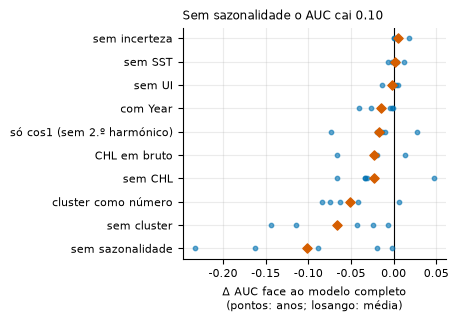

In [19]:
dif = {nome: (auc_loyo(spec) - base).dropna() for nome, spec in VARIANTES.items()}
ordem = sorted(dif, key=lambda n: dif[n].mean(), reverse=True)
fig, ax = plt.subplots(figsize=(3.4, 3.0))
for i, nome in enumerate(ordem):
    ax.scatter(dif[nome], [i] * len(dif[nome]), color=AZUL, s=10, alpha=0.6, zorder=3)
    ax.scatter(dif[nome].mean(), i, color=VERM, marker="D", s=22, zorder=4)
ax.axvline(0, color="k", lw=0.8)
ax.set(yticks=range(len(ordem)), yticklabels=ordem, xlabel="Δ AUC face ao modelo completo\n(pontos: anos; losango: média)",
       title=f"Sem sazonalidade o AUC cai {-dif['sem sazonalidade'].mean():.2f}")
ax.invert_yaxis(); guardar(fig, "10_ablation")

O que mais pesa é a sazonalidade, depois o cluster, o CHL e o 2.º harmónico. Tirar a SST, a UI ou a incerteza muda o AUC bastante menos do que o desvio entre anos (0.078): +0.001, -0.001 e +0.005.

Decisão: nesta fase ficam todas. As diferenças estão dentro do ruído, e o Extra Trees pode usar o que a Logistic Regression ignora. Decido no notebook 04, modelo a modelo, se alguma sai.

In [20]:
ref = json.load(open("reference_numbers.json"))["LOYO_2013_2019"]["LR"]
print("referência:", ref["por_ano"], f"média {ref['media']}")
for nome, spec in [("S0, com log na incerteza", S0), ("SPEC, incerteza em bruto", SPEC)]:
    a = auc_loyo(spec).dropna()
    print(f"{nome}: {a.round(3).tolist()} média {a.mean():.3f}, maior diferença por ano {np.abs(a.to_numpy() - np.array(ref['por_ano'])).max():.3f}")

referência: [0.661, 0.773, 0.86, 0.903, 0.786] média 0.797
S0, com log na incerteza: [0.661, 0.773, 0.86, 0.903, 0.786] média 0.797, maior diferença por ano 0.000
SPEC, incerteza em bruto: [0.673, 0.773, 0.858, 0.898, 0.784] média 0.797, maior diferença por ano 0.012


O S0 reproduz a referência sem diferença. Com a incerteza em bruto (`SPEC`) a média é a mesma, 0.797, mas 2013 sobe 0.012 (0.673 contra 0.661) e passa a tolerância de 0.01 por ano. É a mudança que decidi na secção do log, não um erro nas funções.